# 070 CASE 050 — Coastline: Sandhammaren

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** Has the shoreline at Sandhammaren moved between 2018 and 2025?

**Area:** Sandhammaren, about 25 km east of Ystad (Skåne). Scenes from 3 June 2018 and 14 June 2025.

**Partners:** Swedish Geotechnical Institute (SGI), SMHI, Stockholm University, RISE

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Contains modified Copernicus Sentinel data 2018 and 2025.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus Jupyter and the plotting
libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1abd4653cb843a75557b05c09915fb85904" jupyterlab folium matplotlib
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own DES
account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password; see [digitalearth.se](https://digitalearth.se) for access. Every data fetch goes through
that login, nothing is saved in the notebook, and without a login the fetch stops with an error.
With EGI, the openEO client keeps a refresh token in your home directory so later runs log in
without the browser; on a shared computer account, use the password login instead.
There is no synthetic fallback: every figure comes from real Sentinel-2 data. A run takes about two minutes.

## Log in to Digital Earth Sweden

In [ ]:
from getpass import getpass

import imint.fetch
import openeo
from IPython.display import clear_output

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
try:
    if LOGIN_METHOD == "password":
        user, password = input("DES username: "), getpass("DES password: ")
        if not (user and password):
            raise ValueError("enter both a DES username and a password")
        des.authenticate_basic(user, password)
    else:
        des.authenticate_oidc(provider_id="egi")
finally:
    user = password = None  # never keep the password, even when the login fails
    clear_output()  # keep the typed username and the login link out of a saved notebook


def des_connection(token=None, token_path=None):
    """Every IMINT Engine fetch below uses this login and no other credentials on the machine."""
    return des


assert callable(getattr(imint.fetch, "_connect", None)), "this engine version has no _connect"
imint.fetch._connect = des_connection  # the pinned engine has no public parameter for a connection yet
print("Logged in to Digital Earth Sweden.")


## 1. Method

```
two dates → fetch_des_data → ShorelineAnalyzer (NDWI/MNDWI + Otsu threshold) → water/land map per year → difference
```

`ShorelineAnalyzer` separates water from land with water indices and an automatic (Otsu) threshold,
and classes the result as deep water, shallow water, sediment and land.

## 2. Area and data

The map is interactive when the notebook runs in Jupyter; GitHub's viewer shows only a placeholder for it.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    assert imint.fetch._connect is des_connection, "run the Log in cell first"
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud)
    nodata = np.all(np.stack([a == 0 for a in scene.bands.values()]), axis=0)
    if nodata.mean() > 0.01:  # the archive sometimes holds only part of a scene
        raise ValueError(f"{date}: {nodata.mean():.0%} of the area has no data in this DES scene; use another date")
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud and shadow {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene


def true_colour(scene, top=0.25):
    """True colour with a fixed stretch, so different dates are comparable."""
    return np.clip(np.dstack([scene.bands[b] for b in ("B04", "B03", "B02")]) / top, 0, 1)

AOI = {"west": 14.13, "south": 55.355, "east": 14.22, "north": 55.400}  # Sandhammaren, Ystad
DATES = {2018: "2018-06-03", 2025: "2025-06-14"}

scenes = {year: load_scene(date, AOI) for year, date in DATES.items()}

    Cloud fraction: 0.1%
2018-06-03: 11 bands, 508 x 577 px at 10 m, cloud and shadow 0.1% (SCL), CRS EPSG:3006


    Cloud fraction: 0.0%
2025-06-14: 11 bands, 508 x 577 px at 10 m, cloud and shadow 0.0% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=13, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#6f42c1", weight=2, fill=False, popup="Sandhammaren",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. Water and land per year

In [4]:
from imint.analyzers.shoreline import ShorelineAnalyzer

results = {}
for year, scene in scenes.items():
    res = ShorelineAnalyzer({}).run(rgb=scene.rgb, bands=scene.bands, date=DATES[year], coords=AOI,
                                    output_dir="outputs/050", scl=scene.scl, geo=scene.geo)
    print(year, res.summary())
    results[year] = res.outputs
    print(f"   water fraction {res.outputs['water_fraction']:.3f}, classes {res.outputs['class_fractions']}")

masks = {y: np.asarray(o["shoreline_mask"]) for y, o in results.items()}
water = {y: np.asarray(o["segmentation_map"]) <= 1 for y, o in results.items()}  # 0 deep, 1 shallow water
gained_land = water[2018] & ~water[2025]
lost_land = ~water[2018] & water[2025]
print(f"\nwater → land: {gained_land.sum() * 0.01:.1f} ha, land → water: {lost_land.sum() * 0.01:.1f} ha")

2018 [shoreline] OK — outputs: segmentation_map, shoreline_mask, water_fraction, class_fractions, ndwi
   water fraction 0.606, classes {'water': 0.6018197573656846, 'shallow_water': 0.004366871818665648, 'sediment': 0.013724941661321797, 'land': 0.380088429154328}
2025 [shoreline] OK — outputs: segmentation_map, shoreline_mask, water_fraction, class_fractions, ndwi
   water fraction 0.619, classes {'water': 0.6087351082847746, 'shallow_water': 0.009958514717722676, 'sediment': 0.0009040789312081223, 'land': 0.38040229806629455}

water → land: 0.2 ha, land → water: 36.8 ha


## 4. Results

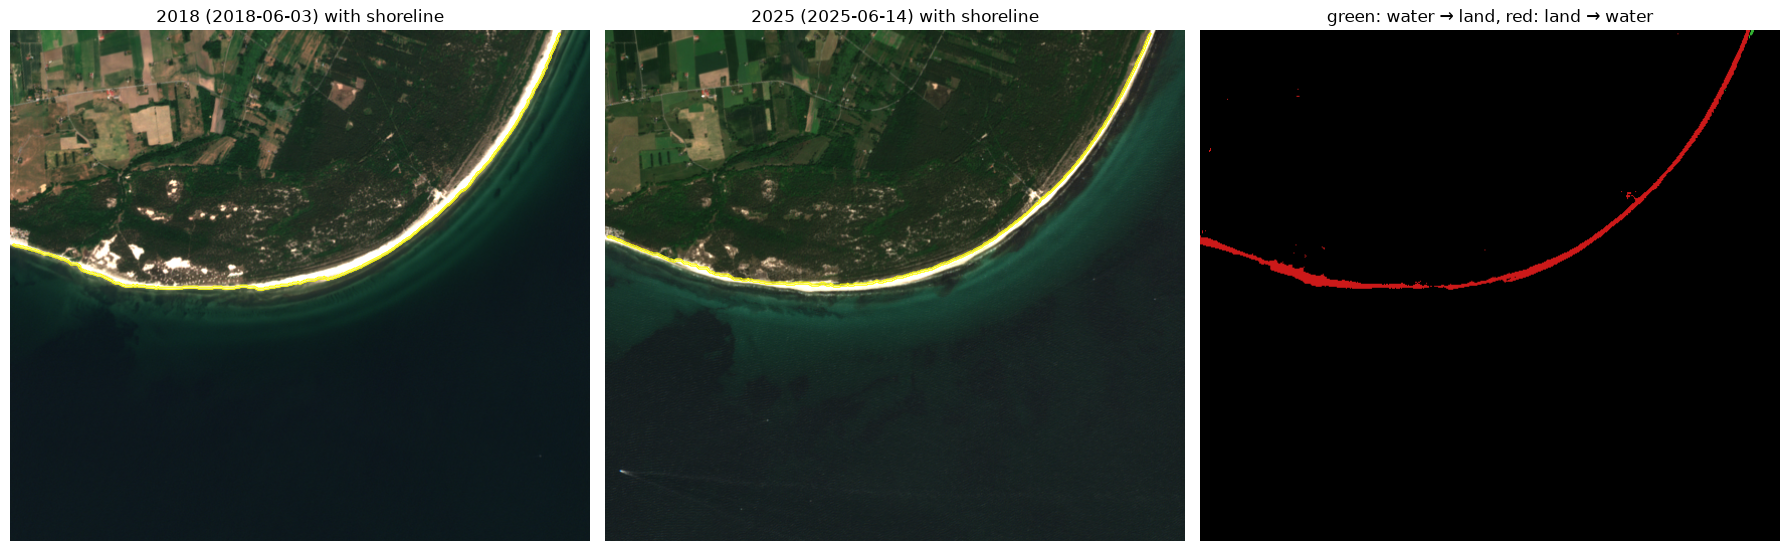

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, year in zip(axes[:2], DATES):
    ax.imshow(true_colour(scenes[year]))
    ax.contour(masks[year], levels=[0.5], colors="yellow", linewidths=0.8)
    ax.set_title(f"{year} ({DATES[year]}) with shoreline")
change = np.zeros(gained_land.shape + (3,))
change[gained_land] = (0.2, 0.7, 0.2)
change[lost_land] = (0.8, 0.1, 0.1)
axes[2].imshow(change)
axes[2].set_title("green: water → land, red: land → water")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Interpretation

In this comparison the change is a narrow band along the whole beach, consistent with the automatic
threshold putting the wet sand on the water side in 2025 and on the land side in 2018. The class
fractions fit that reading:
sediment falls from 1.4 % to 0.1 % of the area while shallow water rises from 0.4 % to 1.0 %. That is a difference between
two single dates, not erosion. Water level, waves and wet sand dominate such comparisons: the
Baltic has no large tide, but wind can raise or lower the water by decimetres. A trend needs many
dates per year, a fixed threshold, and a comparison against SGI's erosion surveys.

**Links:** [`imint/analyzers/shoreline.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/shoreline.py)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).